# ЛР 8. Линейная регрессия: обучение, регуляризация и интерпретация

Цель — `price` (цена аренды в месяц, тг). Данные: `data/astana_rent_clean.csv` — 600 очищенных объявлений (результат ЛР 7). **Отличие от методички:** в этом файле нет признака `dist_center`, поэтому шаги, где он использовался (бины, полиномы), выполнены на другом признаке, а числа отличаются от эталона.

## Шаг 2. Загрузка и разбиение на обучение и тест
Тест откладываем один раз; всё, что считает статистики, определяется только по `train`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_csv("../data/astana_rent_clean.csv")
print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0].to_dict())
train, test = train_test_split(df, test_size=0.25, random_state=42)
print(train.shape, test.shape)

(600, 10)
{'area': 50, 'floor': 2, 'year': 27, 'furniture': 45}
(450, 10) (150, 10)


**Вывод.** В данных 600 объявлений, пропуски остались в `area` (50), `floor` (2), `year` (27) и `furniture` (45): их заполнит Pipeline, чтобы не было утечки. Разбиение 450 / 150, `random_state=42` фиксирует его.

## Шаг 3. Парная регрессия по формуле w = (XᵀX)⁻¹Xᵀy
Один признак — площадь. Столбец единиц отвечает за сдвиг w₀. Строки с пропуском площади пока исключаем.

формула:      [12945.8  4169. ]
LinearRegression: 12945.8 [4169.]


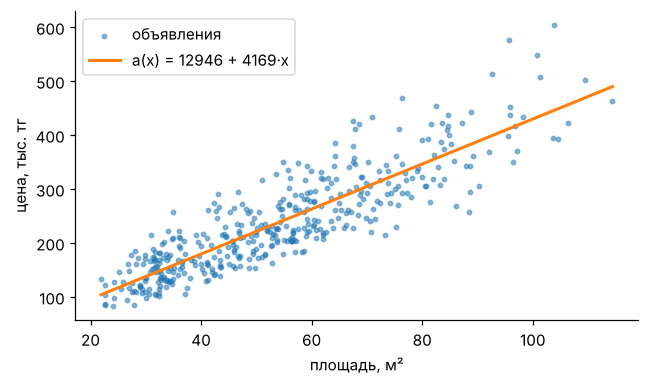

In [2]:
from sklearn.linear_model import LinearRegression

tr = train.dropna(subset=["area"])
X = np.column_stack([np.ones(len(tr)), tr["area"]])
y = tr["price"].to_numpy()

w = np.linalg.solve(X.T @ X, X.T @ y)       # (XᵀX) w = Xᵀy
print("формула:     ", w.round(1))
lr = LinearRegression().fit(tr[["area"]], y)
print("LinearRegression:", round(lr.intercept_, 1), lr.coef_.round(1))

xs = np.linspace(tr["area"].min(), tr["area"].max(), 100)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(tr["area"], tr["price"] / 1000, s=8, alpha=.5, label="объявления")
ax.plot(xs, (w[0] + w[1] * xs) / 1000, color="C1", lw=2, label=f"a(x) = {w[0]:.0f} + {w[1]:.0f}·x")
ax.set_xlabel("площадь, м²"); ax.set_ylabel("цена, тыс. тг"); ax.legend()
plt.tight_layout(); plt.savefig("../reports/fig_pair_regression.png", dpi=150); plt.show()

**Вывод.** Веса из нормального уравнения и из `LinearRegression` совпали: сдвиг ≈ 12 946 тг, наклон ≈ 4 169 тг. Каждый дополнительный квадратный метр добавляет к прогнозу около 4,2 тыс. тг в месяц. В методичке наклон 3 917; отличие объясняется тем, что у нас другая выборка.

## Шаг 4. MSE в векторной форме и качество на тесте

In [3]:
from sklearn.metrics import mean_squared_error, r2_score

mse = np.square(X @ w - y).mean()
print("train MSE", round(mse), " RMSE", round(np.sqrt(mse)))

te = test.dropna(subset=["area"])
pred = lr.predict(te[["area"]])
print("test RMSE", round(np.sqrt(mean_squared_error(te["price"], pred))),
      "R2", round(r2_score(te["price"], pred), 3))

train MSE 2033836459  RMSE 45098
test RMSE 45358 R2 0.786


**Вывод.** Одна площадь объясняет около 79 % разброса цен (R² на тесте 0,786), типичная ошибка ≈ 45 тыс. тг. Ошибка на обучении (45 098) и на тесте (45 358) почти равна, значит модель не переобучена, а просто слишком проста.

### Дополнение к шагу 3. Когда формула «ломается» (вырожденная XᵀX)
Добавим к матрице копию столбца площади и посмотрим, что делают три способа решения.

In [4]:
X2 = np.column_stack([X, X[:, 1]])           # дубликат столбца area
print("ранг XᵀX:", np.linalg.matrix_rank(X2.T @ X2), "из", X2.shape[1])
print("число обусловленности:", f"{np.linalg.cond(X2.T @ X2):.2e}")

try:
    w_inv = np.linalg.inv(X2.T @ X2) @ X2.T @ y
    print("inv:   ", w_inv.round(1))
except np.linalg.LinAlgError as e:
    print("inv:   ошибка —", e)
try:
    print("solve: ", np.linalg.solve(X2.T @ X2, X2.T @ y).round(1))
except np.linalg.LinAlgError as e:
    print("solve: ошибка —", e)
print("lstsq: ", np.linalg.lstsq(X2, y, rcond=None)[0].round(1))

ранг XᵀX: 2 из 3
число обусловленности: 1.94e+35
inv:   ошибка — Singular matrix
solve: ошибка — Singular matrix
lstsq:  [12945.8  2084.5  2084.5]


**Вывод.** После добавления копии столбца ранг XᵀX равен 2 при трёх столбцах, число обусловленности порядка 10³⁵: матрица вырождена. `np.linalg.inv` и `np.linalg.solve` падают с ошибкой `Singular matrix`, потому что единственного решения нет. `np.linalg.lstsq` возвращает решение с минимальной нормой: вес площади делится поровну (2084,5 + 2084,5 = 4169). Тот же эффект даёт полная кодировка one-hot вместе со столбцом единиц.

## Шаг 5. Множественная регрессия в Pipeline
Заполнение пропусков, стандартизация и one-hot — внутри Pipeline: при кросс-валидации параметры считаются только по обучающим фолдам.

In [5]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["rooms", "area", "floor", "floors", "year"]
cat_cols = ["district", "furniture"]
X_train, y_train = train[num_cols + cat_cols], train["price"]
X_test,  y_test  = test[num_cols + cat_cols],  test["price"]

def make_prep(num=num_cols):
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cat_cols))

model = make_pipeline(make_prep(), LinearRegression())
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
print(scores.round(3), scores.mean().round(3))
model.fit(X_train, y_train)
print("test R2", round(model.score(X_test, y_test), 3))

names = [n.split("__")[1] for n in model[:-1].get_feature_names_out()]
coefs = pd.Series(model[-1].coef_, index=names)
print(coefs.round(0).sort_values())

[0.881 0.798 0.826 0.867 0.902] 0.855
test R2 0.91
district_Алматы     -31507.0
district_Байконур   -22278.0
district_Сарыарка   -17369.0
furniture_no         -6428.0
floor                -1749.0
floors                 -24.0
furniture_yes         6428.0
district_Нура        14317.0
year                 14456.0
rooms                32383.0
area                 54314.0
district_Есиль       56836.0
dtype: float64


**Вывод.** R² на кросс-валидации по фолдам 0,80–0,90, среднее 0,855; на тесте 0,91. Числовые признаки стандартизованы, поэтому их веса сопоставимы: самый сильный числовой признак — площадь (+54 тыс. тг на одно стандартное отклонение), следом число комнат и год. Среди районов дороже всех Есиль (+56,8 тыс.), дешевле всех Алматы (−31,5 тыс.). Веса `furniture_no` и `furniture_yes` равны по модулю и противоположны по знаку: сумма этих one-hot столбцов всегда равна 1, то есть они линейно зависимы (см. шаг 8).

## Шаг 6. Нелинейный признак: бинаризация
В методичке бинируется `dist_center`; у нас его нет. Выберем числовой признак по графику цены за м² и проверим бины на кросс-валидации. Выбор делаем только по `train`.

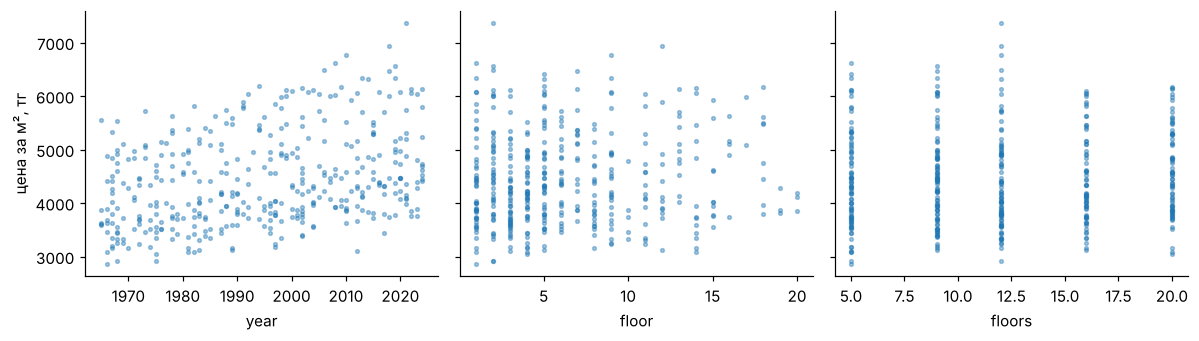

без бинов: 0.8549
бины year   n_bins=4: cv R2 = 0.8492 ± 0.038


бины year   n_bins=8: cv R2 = 0.8521 ± 0.037
бины area   n_bins=4: cv R2 = 0.8232 ± 0.023
бины area   n_bins=8: cv R2 = 0.8409 ± 0.025


бины floor  n_bins=4: cv R2 = 0.8526 ± 0.040
бины floor  n_bins=8: cv R2 = 0.8505 ± 0.040


In [6]:
from sklearn.preprocessing import KBinsDiscretizer

d = train.dropna(subset=["area"]).copy()
d["pm2"] = d["price"] / d["area"]
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, col in zip(axs, ["year", "floor", "floors"]):
    dd = d.dropna(subset=[col])
    ax.scatter(dd[col], dd["pm2"], s=6, alpha=.4)
    ax.set_xlabel(col)
axs[0].set_ylabel("цена за м², тг")
plt.tight_layout(); plt.savefig("../reports/fig_pm2_vs_features.png", dpi=150); plt.show()

def make_prep_bins(bin_col, n_bins=8, strategy="uniform"):
    rest = [c for c in num_cols if c != bin_col]
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), rest),
        (make_pipeline(SimpleImputer(strategy="median"),
                       KBinsDiscretizer(n_bins=n_bins, encode="onehot", strategy=strategy)), [bin_col]),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cat_cols))

print("без бинов:", cross_val_score(model, X_train, y_train, cv=5, scoring="r2").mean().round(4))
for col in ["year", "area", "floor"]:
    for nb in (4, 8):
        m = make_pipeline(make_prep_bins(col, nb), LinearRegression())
        s = cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
        print(f"бины {col:6s} n_bins={nb}: cv R2 = {s.mean():.4f} ± {s.std():.3f}")

**Вывод.** Бины не помогли: R² на кросс-валидации без бинов 0,8549, с бинами по `year` 0,849–0,852, по `floor` 0,851–0,853, по `area` 0,823–0,841. Ни один вариант не превзошёл базовую модель, разброс между фолдами (≈ 0,04) больше любых различий. Значит, для имеющихся признаков линейной зависимости достаточно: нелинейного признака вроде `dist_center` из методички в этих данных нет. Параметры бинов оставлены в `params.json` для эксперимента, но улучшения от них мы не ждём.

```
git add notebooks/lab8.ipynb
git commit -m "Ноутбук: парная и множественная регрессия, бины"
```

## Шаг 7. Переобучение и регуляризация на малой выборке
30 объявлений, цель — цена за м², признак — площадь (в методичке — `dist_center`, у нас его нет; на годе постройки переобучение почти не видно, поэтому берём площадь). Полиномы степени 1, 4 и 15; признаки стандартизуем.

In [7]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

base = train.dropna(subset=["area", "year"]).copy()
base["pm2"] = base["price"] / base["area"]
small = base.sample(30, random_state=1)
big = test.dropna(subset=["area", "year"]).copy()
big["pm2"] = big["price"] / big["area"]
xs, ys = small[["area"]], small["pm2"]
xb, yb = big[["area"]], big["pm2"]

def rmse(m, X, y): return round(np.sqrt(mean_squared_error(y, m.predict(X))))
def poly(deg, reg):
    return make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), reg)

for deg in [1, 4, 15]:
    m = poly(deg, LinearRegression()).fit(xs, ys)
    print(deg, "train RMSE", rmse(m, xs, ys), "test RMSE", rmse(m, xb, yb),
          "max|w|", f"{np.abs(m[-1].coef_).max():.3g}")
for a in [0.01, 1, 100]:
    m = poly(15, Ridge(alpha=a)).fit(xs, ys)
    print("ridge", a, "train", rmse(m, xs, ys), "test", rmse(m, xb, yb),
          "max|w|", f"{np.abs(m[-1].coef_).max():.3g}")

1 train RMSE 872 test RMSE 878 max|w| 331
4 train RMSE 794 test RMSE 1158 max|w| 8.42e+04
15 train RMSE 763 test RMSE 268448 max|w| 3.67e+06
ridge 0.01 train 800 test 4635 max|w| 872
ridge 1 train 815 test 2109 max|w| 699
ridge 100 train 899 test 832 max|w| 57.6


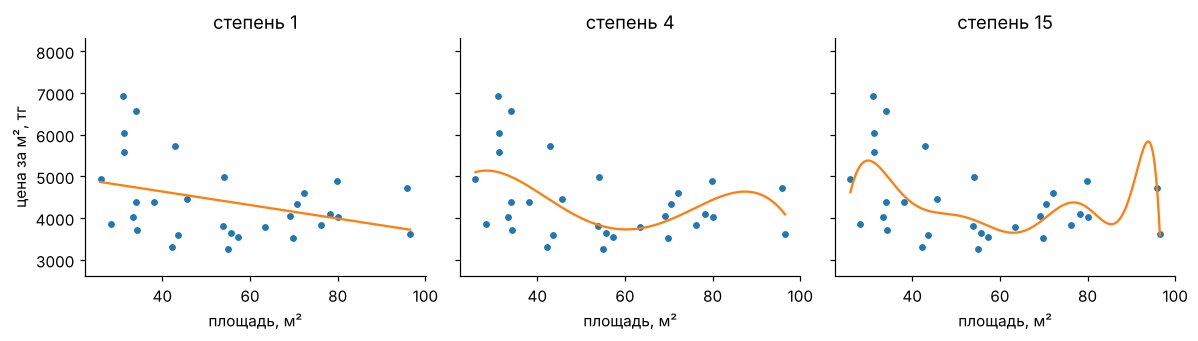

In [8]:
grid = pd.DataFrame({"area": np.linspace(xs["area"].min(), xs["area"].max(), 300)})
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, deg in zip(axs, [1, 4, 15]):
    m = poly(deg, LinearRegression()).fit(xs, ys)
    ax.scatter(xs["area"], ys, s=12); ax.plot(grid["area"], m.predict(grid), color="C1")
    ax.set_title(f"степень {deg}"); ax.set_xlabel("площадь, м²")
axs[0].set_ylabel("цена за м², тг"); axs[0].set_ylim(ys.min() * .8, ys.max() * 1.2)
plt.tight_layout(); plt.savefig("../reports/fig_poly.png", dpi=150); plt.show()

**Вывод.** Признак — площадь, объектов 30. Чем выше степень полинома, тем меньше ошибка на обучении (872 → 794 → 763) и тем больше на тесте (878 → 1 158 → 268 448); веса полинома степени 15 достигают миллионов (3,7·10⁶) — классический симптом переобучения. Ridge возвращает порядок: при α = 100 ошибка на тесте 832 (лучше, чем у прямой), веса уменьшились на пять порядков. При маленьком α (0,01) штрафа недостаточно (4 635), а слишком большой α превратит модель в константу, поэтому α подбирают на кросс-валидации.

## Шаг 8. Ridge и Lasso с подбором α
Возвращаемся к полной модели из шага 5. `RidgeCV` и `LassoCV` перебирают сетку α по кросс-валидации внутри обучающей выборки.

ridge alpha 2.593 cv 0.855 test 0.91 zeros 0 of 12


lasso alpha 221.222 cv 0.854 test 0.91 zeros 3 of 12


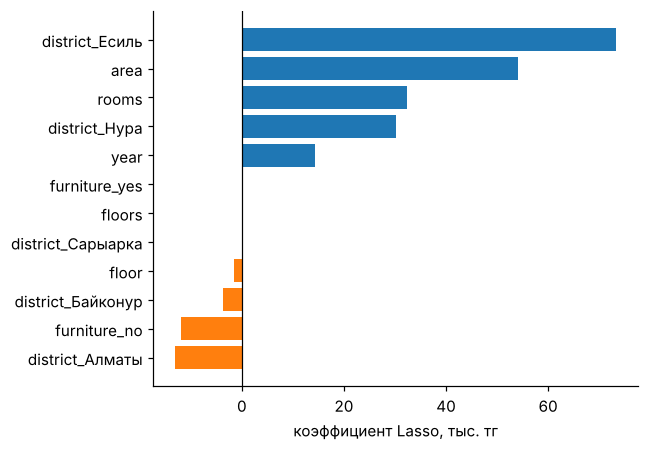

{'district_Алматы': -13019.0, 'furniture_no': -12005.0, 'district_Байконур': -3603.0, 'floor': -1451.0, 'district_Сарыарка': -0.0, 'floors': -0.0, 'furniture_yes': 0.0, 'year': 14259.0, 'district_Нура': 30199.0, 'rooms': 32343.0, 'area': 54056.0, 'district_Есиль': 73285.0}


In [9]:
from sklearn.linear_model import RidgeCV, LassoCV

regs = {"ridge": RidgeCV(alphas=np.logspace(-2, 3, 30)),
        "lasso": LassoCV(alphas=np.logspace(0, 4, 30), cv=5, random_state=42, max_iter=50000)}
fitted = {}
for name, reg in regs.items():
    m = make_pipeline(make_prep(), reg)
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring="r2").mean()
    m.fit(X_train, y_train)
    zeros = int((np.abs(m[-1].coef_) < 1e-6).sum())
    fitted[name] = m
    print(name, "alpha", round(m[-1].alpha_, 3), "cv", cv.round(3),
          "test", round(m.score(X_test, y_test), 3), "zeros", zeros, "of", len(m[-1].coef_))

lasso = fitted["lasso"]
cf = pd.Series(lasso[-1].coef_, index=[n.split("__")[1] for n in lasso[:-1].get_feature_names_out()]).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.barh(cf.index, cf.values / 1000, color=["C1" if v < 0 else "C0" for v in cf.values])
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("коэффициент Lasso, тыс. тг")
plt.tight_layout(); plt.savefig("../reports/fig_lasso_coefs.png", dpi=150); plt.show()
print(cf.round(0).to_dict())

**Вывод.** `RidgeCV` выбрал α ≈ 2,6, `LassoCV` — α ≈ 221. Качество обеих моделей совпало с обычной регрессией (cv R² 0,855 и 0,854, тест 0,91): на 450 объектах и 12 признаках переобучения нет, и регуляризация не дала выигрыша. Lasso обнулил три веса: `district_Сарыарка` (опорная категория района), `furniture_yes` и `floors`. Обнуление `furniture_yes` — это отбор внутри группы one-hot: один из двух столбцов линейно зависим от другого и лишний. Оставшиеся веса читаются относительно обнулённой категории: квартира без мебели дешевле примерно на 12 тыс. тг.

## Шаг 9. Важность признаков через удаление
Удаляем признак, заново оцениваем модель на кросс-валидации и смотрим падение R². В отличие от весов, этот способ не зависит от кодирования.

0.855
district     0.137
area         0.089
year         0.026
rooms        0.020
furniture    0.004
floor       -0.000
floors      -0.001
dtype: float64


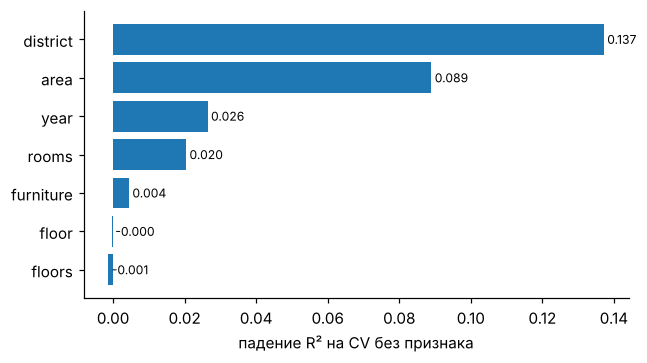

       rooms  area
rooms   1.00  0.91
area    0.91  1.00


In [10]:
base_cv = cross_val_score(make_pipeline(make_prep(), Ridge(alpha=1)),
                          X_train, y_train, cv=5, scoring="r2").mean()
drop = {}
for col in num_cols + cat_cols:
    nn = [c for c in num_cols if c != col]
    cc = [c for c in cat_cols if c != col]
    prep = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nn),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cc))
    s = cross_val_score(make_pipeline(prep, Ridge(alpha=1)),
                        X_train, y_train, cv=5, scoring="r2").mean()
    drop[col] = base_cv - s
imp = pd.Series(drop).sort_values(ascending=False)
print(round(base_cv, 3)); print(imp.round(3))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.barh(imp.index[::-1], imp.values[::-1], color="C0")
for i, v in enumerate(imp.values[::-1]): ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
ax.set_xlabel("падение R² на CV без признака")
plt.tight_layout(); plt.savefig("../reports/fig_importance.png", dpi=150); plt.show()

print(train[["rooms", "area"]].corr().round(2))

**Вывод.** Главное для цены — район (падение R² на 0,137), затем площадь (0,089); год постройки (0,026) и число комнат (0,020) заметно слабее. Мебель, этаж и этажность практически ничего не добавляют (≈ 0). Число комнат имеет второй по величине числовой вес в шаге 5 (32 тыс. тг), но его удаление уменьшает R² лишь на 0,020: корреляция комнат и площади равна 0,91, и площадь «забирает» почти всю информацию. Это пример того, почему большой вес не равен большой важности.